In [4]:
import glob
import os
from pathlib import Path
from random import choice, choices

import autoroot
import hydra
import matplotlib.pyplot as plt
import numpy as np
import scipy
import torch
from omegaconf import OmegaConf
from torch import nn

from src.data.lf.lf_datamodule import LF
from src.modules.lit_module import LitModule
from src.modules.models.sequential import SequentialModel
from src.utils import initialize_resolvers
from src.utils.tools import get_rho_lstsq

initialize_resolvers()

In [5]:
def get_lastest_ckpt(path):
    path = Path(path)
    ckpt = max((path).glob("*.ckpt"), key=os.path.getctime)
    return ckpt


def data_illustration(inputs, outputs, index=0, yhat=None):

    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    ax[0].plot(inputs[index, :, 0].numpy(), label="x")
    ax[0].plot(outputs[index, :, 0].numpy(), label="y")
    if yhat is not None:
        ax[0].plot(yhat[index, :, 0].numpy(), label="yhat")
    ax[0].legend()

    ax[1].plot(get_rho_lstsq(inputs, outputs, end_point=False)[:, 0], label="rho")
    if yhat is not None:
        ax[1].plot(get_rho_lstsq(inputs, yhat, end_point=False)[:, 0], label="rho_hat")
    ax[1].legend()

In [6]:
data = LF(
    data_dir="",
    N=20,
    T=1024,
    D=1,
    rho_name="exponential",
    rho_param={"alpha": 1},
    input_generator="randn",
    # processing=["smooth_noise"],
    manual_seed=0,
).dataset_construction()
index = 4

Seed set to 0


In [7]:
data1 = data[0]
path = "./logs/train/2025-01-21_12-59-42/checkpoints"
model = LitModule.load_from_checkpoint(get_lastest_ckpt(path))
model.eval()
model = model.to("cpu")
yhat = model(data1[:][0]).detach()

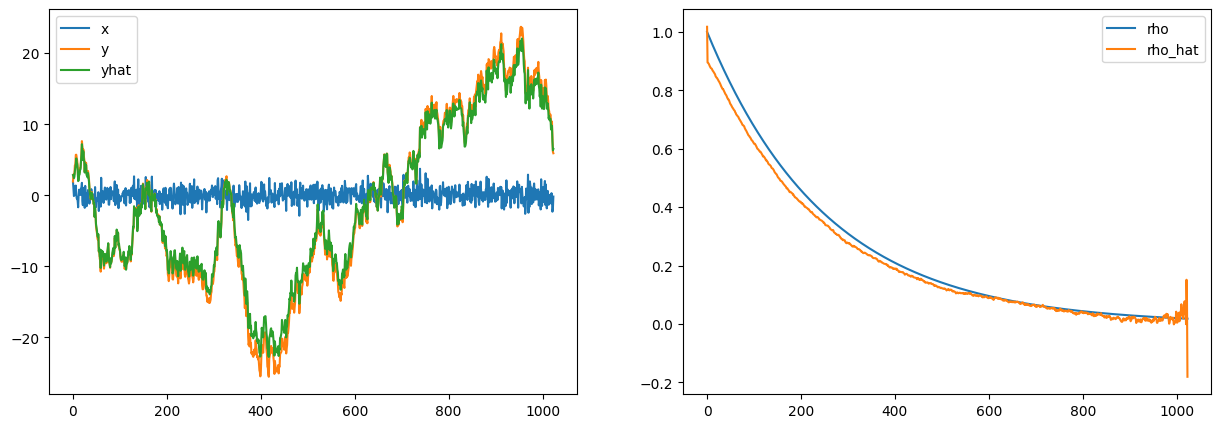

In [8]:
data_illustration(data1[:][0], data1[:][1], index=index, yhat=yhat)